# **Loading data**

In [ ]:
from google.colab import drive
drive.mount("/content/gdrive", force_remount=True)

Mounted at /content/gdrive


In [ ]:
import pandas as pd

train_data = pd.read_csv("gdrive/My Drive/Colab Notebooks/train.csv")
train_variables = train_data.drop(columns=["id", "exam_score"])
target = train_data["exam_score"]
train_data.shape

(630000, 13)

In [ ]:
train_data.head()

,id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,0,21,female,b.sc,7.91,98.8,no,4.9,average,online videos,low,easy,78.3
1,1,18,other,diploma,4.95,94.8,yes,4.7,poor,self-study,medium,moderate,46.7
2,2,20,female,b.sc,4.68,92.6,yes,5.8,poor,coaching,high,moderate,99.0
3,3,19,male,b.sc,2.00,49.5,yes,8.3,average,group study,high,moderate,63.9
4,4,23,male,bca,7.65,86.9,yes,9.6,good,self-study,high,easy,100.0


In [ ]:
test_data = pd.read_csv("gdrive/My Drive/Colab Notebooks/test.csv")
test_variables = test_data.drop(columns=["id"])
test_data.shape

(270000, 12)

In [ ]:
test_data.head()

,id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty
0,630000,24,other,ba,6.85,65.2,yes,5.2,poor,group study,high,easy
1,630001,18,male,diploma,6.61,45.0,no,9.3,poor,coaching,low,easy
2,630002,24,female,b.tech,6.60,98.5,yes,6.2,good,group study,medium,moderate
3,630003,24,male,diploma,3.03,66.3,yes,5.7,average,mixed,medium,moderate
4,630004,20,female,b.tech,2.03,42.4,yes,9.2,average,coaching,low,moderate


In [ ]:
sample_submission = pd.read_csv("gdrive/My Drive/Colab Notebooks/sample_submission.csv")
sample_submission.head()

,id,exam_score
0,630000,0
1,630001,0
2,630002,0
3,630003,0
4,630004,0


# **Preprocessing**

Check for missing values

In [ ]:
train_data.isnull().sum()

,0
id,0
age,0
gender,0
course,0
study_hours,0
class_attendance,0
internet_access,0
sleep_hours,0
sleep_quality,0
study_method,0


In [ ]:
test_data.isnull().sum()

,0
id,0
age,0
gender,0
course,0
study_hours,0
class_attendance,0
internet_access,0
sleep_hours,0
sleep_quality,0
study_method,0


Check for duplicates

In [ ]:
train_data.duplicated().sum()

np.int64(0)

In [ ]:
test_data.duplicated().sum()

np.int64(0)

Split the training data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(train_variables, target, test_size=0.2, random_state=42)
X_train.shape

(504000, 11)

Remove features weakly correlated with exam score

Correlation with exam score:
study_hours         0.762415
class_attendance    0.362447
sleep_hours         0.167702
age                 0.010552
dtype: float64


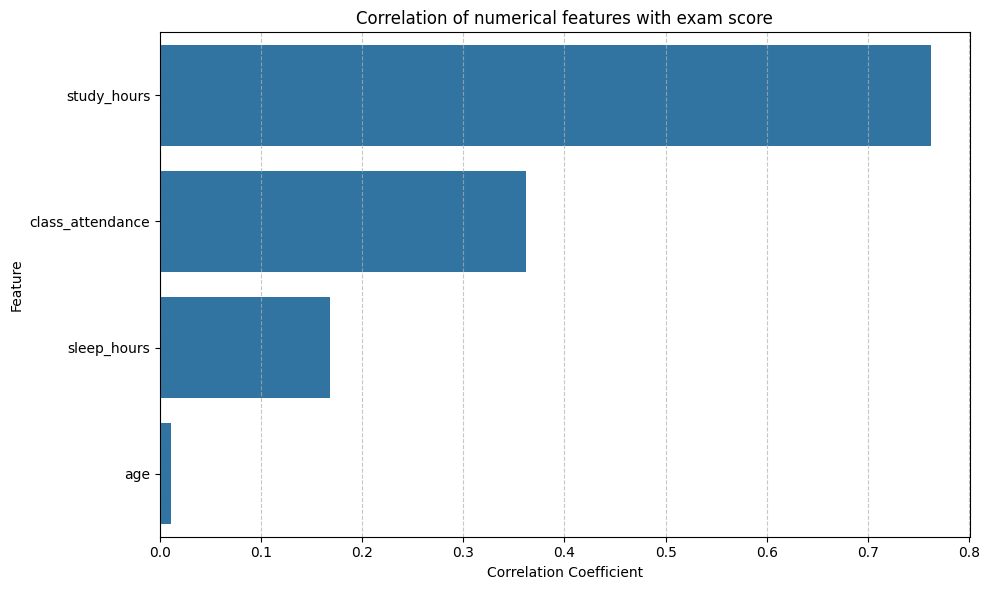

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
correlations = X_train[numerical_cols].corrwith(y_train).sort_values(ascending=False)

print("Correlation with exam score:")
print(correlations)

plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title("Correlation of numerical features with exam score")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

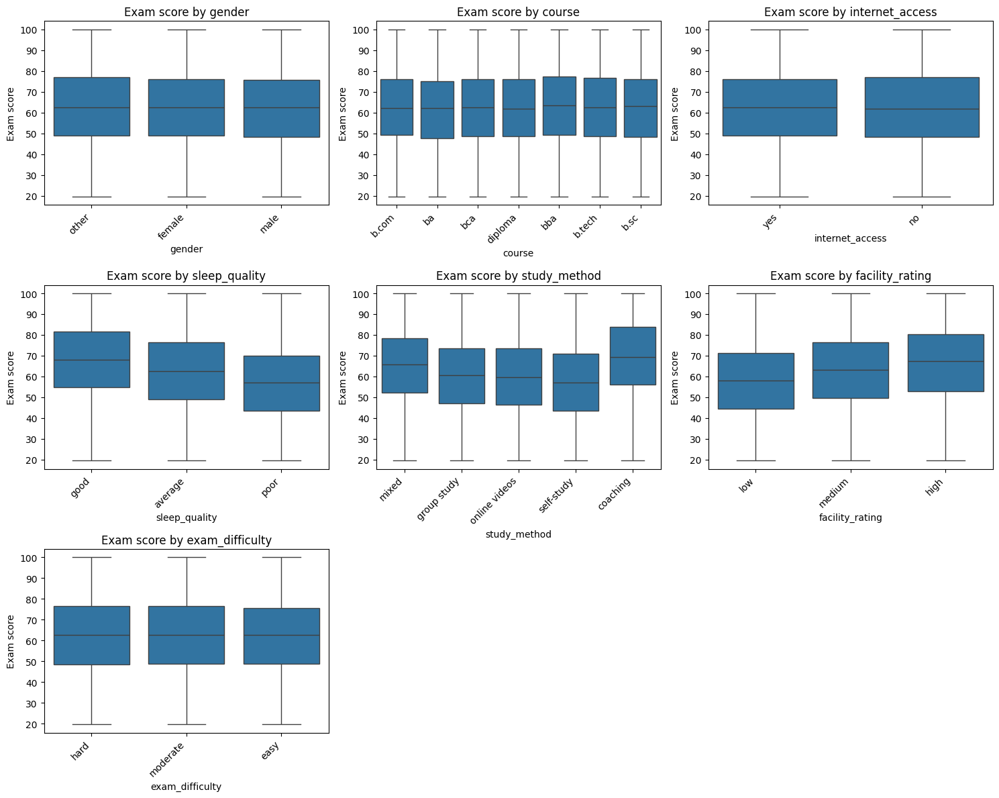

In [ ]:
train_df_for_plot = X_train.copy()
train_df_for_plot["exam_score"] = y_train

categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns

plt.figure(figsize=(15, 12))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(data=train_df_for_plot, x=col, y="exam_score")
    plt.title(f"Exam score by {col}")
    plt.xlabel(col)
    plt.ylabel("Exam score")
    plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
columns_to_drop = ["age", "gender", "internet_access", "exam_difficulty"]

X_train = X_train.drop(columns=columns_to_drop)
X_test = X_test.drop(columns=columns_to_drop)
test_variables = test_variables.drop(columns=columns_to_drop)
X_train.head()

,course,study_hours,class_attendance,sleep_hours,sleep_quality,study_method,facility_rating
625149,b.com,0.84,79.0,9.9,good,mixed,low
276435,b.com,3.35,94.2,6.0,good,group study,medium
43949,ba,2.20,87.5,6.8,good,online videos,high
280523,bca,3.10,64.0,7.6,average,self-study,medium
619977,diploma,1.44,56.2,5.5,average,online videos,medium


Encode categorical columns

In [ ]:
categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns
X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)
test_variables = pd.get_dummies(test_variables, columns=categorical_cols, drop_first=True)
X_train.head()

,study_hours,class_attendance,sleep_hours,course_b.sc,course_b.tech,course_ba,course_bba,course_bca,course_diploma,sleep_quality_good,sleep_quality_poor,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,facility_rating_low,facility_rating_medium
625149,0.84,79.0,9.9,False,False,False,False,False,False,True,False,False,True,False,False,True,False
276435,3.35,94.2,6.0,False,False,False,False,False,False,True,False,True,False,False,False,False,True
43949,2.20,87.5,6.8,False,False,True,False,False,False,True,False,False,False,True,False,False,False
280523,3.10,64.0,7.6,False,False,False,False,True,False,False,False,False,False,False,True,False,True
619977,1.44,56.2,5.5,False,False,False,False,False,True,False,False,False,False,True,False,False,True


Remove low variance features

In [ ]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.1)
selector.set_output(transform="pandas")
selector.fit(X_train)

X_train_vt = selector.transform(X_train)
X_test_vt = selector.transform(X_test)
encoded_test_var_vt = selector.transform(test_variables)

print(f"Original number of features in X_train: {X_train.shape[1]}")
print(f"Number of features after VarianceThreshold: {X_train_vt.shape[1]}")

features_kept = selector.get_feature_names_out()
original_features = X_train.columns
features_removed = [col for col in original_features if col not in features_kept]

print(f"Features removed by VarianceThreshold: {features_removed}")

X_train = X_train_vt
X_test = X_test_vt
test_variables = encoded_test_var_vt

Original number of features in X_train: 17
Number of features after VarianceThreshold: 15
Features removed by VarianceThreshold: ['course_ba', 'course_diploma']


Clip outliers

In [ ]:
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns

lower_bounds = X_train[numerical_cols].quantile(0.01)
upper_bounds = X_train[numerical_cols].quantile(0.99)

X_train[numerical_cols] = X_train[numerical_cols].clip(lower=lower_bounds, upper=upper_bounds, axis=1)
X_test[numerical_cols] = X_test[numerical_cols].clip(lower=lower_bounds, upper=upper_bounds, axis=1)
test_variables[numerical_cols] = test_variables[numerical_cols].clip(lower=lower_bounds, upper=upper_bounds, axis=1)

Scale the data

In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
scaler = StandardScaler()
scaler.fit(X_train[numerical_cols])
X_train[numerical_cols] = scaler.transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])
test_variables[numerical_cols] = scaler.fit_transform(test_variables[numerical_cols])
X_train.head()

,study_hours,class_attendance,sleep_hours,course_b.sc,course_b.tech,course_bba,course_bca,sleep_quality_good,sleep_quality_poor,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,facility_rating_low,facility_rating_medium
625149,-1.338741,0.402461,1.621143,False,False,False,False,True,False,False,True,False,False,True,False
276435,-0.275043,1.274289,-0.614920,False,False,False,False,True,False,True,False,False,False,False,True
43949,-0.762395,0.889997,-0.156240,False,False,False,False,True,False,False,False,True,False,False,False
280523,-0.380989,-0.457896,0.302439,False,False,False,True,False,False,False,False,False,True,False,True
619977,-1.084471,-0.905281,-0.901595,False,False,False,False,False,False,False,False,True,False,False,True


# **Linear regression**

Test model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print(f"Linear Regression Model Performance:")
print(f"  Mean Squared Error (MSE): {mse_linear:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_linear:.2f}")
print(f"  R-squared (R2): {r2_linear:.2f}")

Linear Regression Model Performance:
  Mean Squared Error (MSE): 78.98
  Root Mean Squared Error (RMSE): 8.89
  R-squared (R2): 0.78


Visualize results

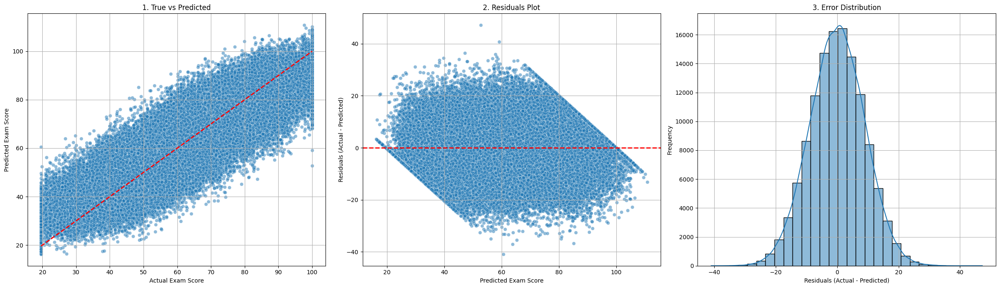

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

residuals = y_test - y_pred_linear

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_linear, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_linear, y=residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test data and save

In [ ]:
test_pred_linear = linear_model.predict(test_variables)

sample_submission["exam_score"] = test_pred_linear
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_linear.csv", index=False)

# **Polynomial regression**

Test model

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

poly_feat = PolynomialFeatures(degree=2)
poly_feat.fit(X_train)
X_train_poly = poly_feat.transform(X_train)
X_test_poly = poly_feat.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

y_pred_poly = poly_model.predict(X_test_poly)

mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print(f"Polynomial Regression Model (Degree 2) Performance:")
print(f"  Mean Squared Error (MSE): {mse_poly:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_poly:.2f}")
print(f"  R-squared (R2): {r2_poly:.2f}")

Polynomial Regression Model (Degree 2) Performance:
  Mean Squared Error (MSE): 78.84
  Root Mean Squared Error (RMSE): 8.88
  R-squared (R2): 0.78


Visualize results

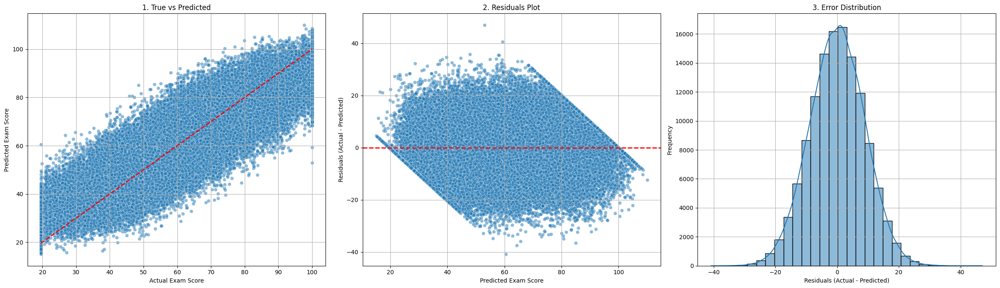

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

residuals = y_test - y_pred_poly

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_poly, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_poly, y=residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test data and save

In [ ]:
test_data_poly = poly_feat.fit_transform(test_variables)
test_pred_poly = poly_model.predict(test_data_poly)

sample_submission["exam_score"] = test_pred_poly
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_poly.csv", index=False)

# **Support Vector Regression (SVR)**

Take a smaller sample of data

In [ ]:
X_train_sample = X_train.sample(n=20000, random_state=42)
y_train_sample = y_train.sample(n=20000, random_state=42)

Find best hyperparameters on small sample

In [ ]:
param_grid_svr = [
    {
        "kernel": ["linear"],
        "C": [i for i in range(1, 1000, 10)],
        "epsilon": [0.001, 0.01, 0.1, 0.2, 0.5, 1.0]
    },
    {
        "kernel": ["poly"],
        "degree": [2, 3, 4],
        "gamma": ["scale", "auto"],
        "C": [i for i in range(1, 1000, 10)],
        "epsilon": [0.001, 0.01, 0.1, 0.2, 0.5, 1.0]
    },
    {
        "kernel": ["rbf", "sigmoid"],
        "gamma": ["scale", "auto"],
        "C": [i for i in range(1, 1000, 10)],
        "epsilon": [0.001, 0.01, 0.1, 0.2, 0.5, 1.0]
    }
]

In [ ]:
from sklearn.svm import SVR
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

svr_model = SVR()
random_search_svr = HalvingRandomSearchCV(svr_model, param_grid_svr, scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1, verbose=3)
random_search_svr.fit(X_train_sample, y_train_sample)

best_svr_model = random_search_svr.best_estimator_
print(f"Best SVR model parameters: {random_search_svr.best_params_}")

n_iterations: 7
n_required_iterations: 7
n_possible_iterations: 7
min_resources_: 10
max_resources_: 20000
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 2000
n_resources: 10
Fitting 5 folds for each of 2000 candidates, totalling 10000 fits
----------
iter: 1
n_candidates: 667
n_resources: 30
Fitting 5 folds for each of 667 candidates, totalling 3335 fits
----------
iter: 2
n_candidates: 223
n_resources: 90
Fitting 5 folds for each of 223 candidates, totalling 1115 fits
----------
iter: 3
n_candidates: 75
n_resources: 270
Fitting 5 folds for each of 75 candidates, totalling 375 fits
----------
iter: 4
n_candidates: 25
n_resources: 810
Fitting 5 folds for each of 25 candidates, totalling 125 fits
----------
iter: 5
n_candidates: 9
n_resources: 2430
Fitting 5 folds for each of 9 candidates, totalling 45 fits
----------
iter: 6
n_candidates: 3
n_resources: 7290
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best SVR model parameters: {'kernel': 'line

Test model with best hyperparameters on larger sample

In [ ]:
X_train_sample_1 = X_train.sample(n=50000, random_state=42)
y_train_sample_1 = y_train.sample(n=50000, random_state=42)

best_svr_model.fit(X_train_sample_1, y_train_sample_1)
y_pred_svr = best_svr_model.predict(X_test)

mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print(f"Support Vector Regression (SVR) Model Performance:")
print(f"  Mean Squared Error (MSE): {mse_svr:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_svr:.2f}")
print(f"  R-squared (R2): {r2_svr:.2f}")

Support Vector Regression (SVR) Model Performance:
  Mean Squared Error (MSE): 79.10
  Root Mean Squared Error (RMSE): 8.89
  R-squared (R2): 0.78


Visualize results

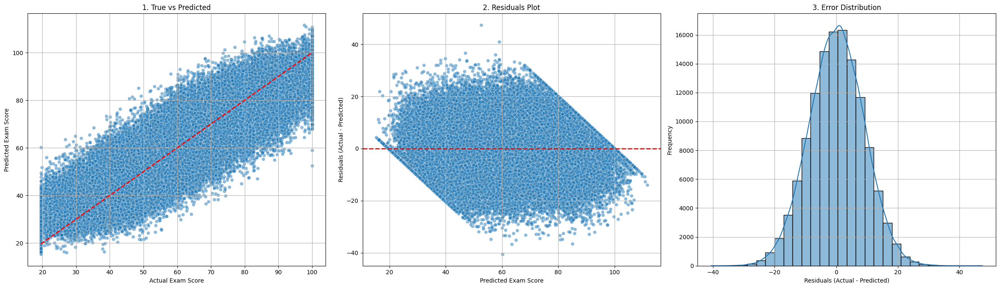

In [ ]:
residuals_svr = y_test - y_pred_svr

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_svr, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_svr, y=residuals_svr, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals_svr, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test data and save

In [ ]:
test_pred_svr = best_svr_model.predict(test_variables)

sample_submission["exam_score"] = test_pred_svr
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_svr.csv", index=False)

# **Decision Tree**

Find best hyperparameters

In [ ]:
param_grid_dt = [
    {
        "max_depth": [2, 4, 8, 16, 32],
        "min_samples_split": [2, 4, 6, 8, 10],
        "min_samples_leaf": [1, 3, 5, 7, 9]
    }
]

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

dt_model = DecisionTreeRegressor(random_state=42)
grid_search_dt = GridSearchCV(dt_model, param_grid_dt, scoring="neg_root_mean_squared_error", cv=3, n_jobs=-1, verbose=3)
grid_search_dt.fit(X_train, y_train)

best_dt_model = grid_search_dt.best_estimator_
print(f"Best Decision Tree model parameters: {grid_search_dt.best_params_}")

Fitting 3 folds for each of 125 candidates, totalling 375 fits
Best Decision Tree model parameters: {'max_depth': 16, 'min_samples_leaf': 9, 'min_samples_split': 2}


Test model with best hyperparameters

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

best_dt_model.fit(X_train, y_train)
y_pred_dt = best_dt_model.predict(X_test)

mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print(f"Decision Tree Regressor Performance:")
print(f"  Mean Squared Error (MSE): {mse_dt:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_dt:.2f}")
print(f"  R-squared (R2): {r2_dt:.2f}")

Decision Tree Regressor Performance:
  Mean Squared Error (MSE): 92.26
  Root Mean Squared Error (RMSE): 9.61
  R-squared (R2): 0.74


Visualize results

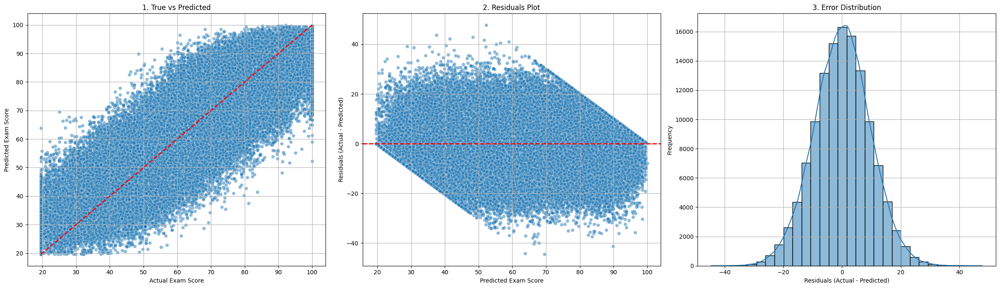

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals_dt = y_test - y_pred_dt

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_dt, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_dt, y=residuals_dt, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals_dt, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Visualize plot tree

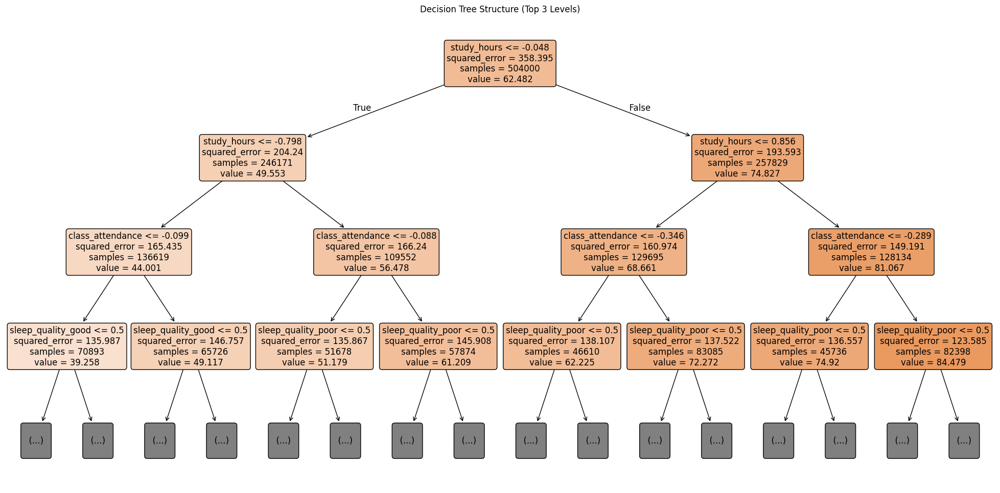

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 12))
plot_tree(best_dt_model,
          max_depth=3,
          feature_names=X_train.columns,
          filled=True,
          rounded=True,
          fontsize=12)

plt.title("Decision Tree Structure (Top 3 Levels)")
plt.show()

Apply model to real test data and save

In [ ]:
test_pred_dt = best_dt_model.predict(test_variables)

sample_submission["exam_score"] = test_pred_dt
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_dt.csv", index=False)

# **Random Forest**

Take a smaller sample of data

In [ ]:
X_train_sample = X_train.sample(n=20000, random_state=42)
y_train_sample = y_train.sample(n=20000, random_state=42)

Find best hyperparameters on small sample

In [ ]:
param_grid_rf = [
    {
        "max_depth": [None, 2, 4, 8, 16],
        "min_samples_split": [2, 4, 6, 8],
        "min_samples_leaf": [1, 3, 5, 7]
    }
]

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
grid_search_rf = GridSearchCV(rf_model, param_grid_rf, cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=3)
grid_search_rf.fit(X_train_sample, y_train_sample)

best_rf_model = grid_search_rf.best_estimator_
print(f"Best Random Forest model parameters: {grid_search_rf.best_params_}")

Fitting 3 folds for each of 80 candidates, totalling 240 fits
Best Random Forest model parameters: {'max_depth': None, 'min_samples_leaf': 7, 'min_samples_split': 2}


Test model with best hyperparameters

In [ ]:
best_rf_model.fit(X_train, y_train)
y_pred_rf = best_rf_model.predict(X_test)

mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Decision Tree Regressor Performance:")
print(f"  Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_rf:.2f}")
print(f"  R-squared (R2): {r2_rf:.2f}")

Decision Tree Regressor Performance:
  Mean Squared Error (MSE): 81.30
  Root Mean Squared Error (RMSE): 9.02
  R-squared (R2): 0.77


Visualize results

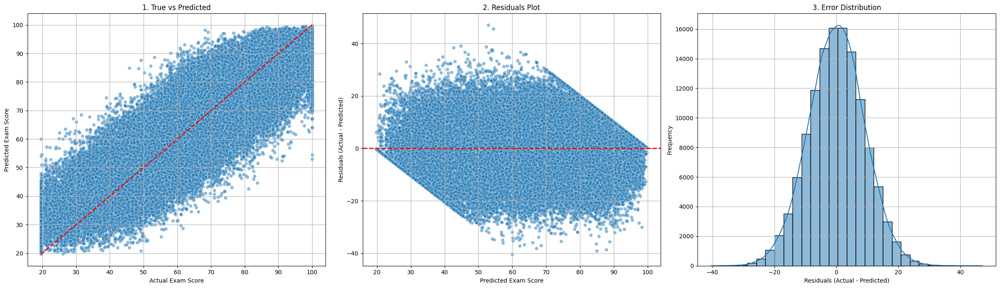

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals_rf = y_test - y_pred_rf

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_rf, y=residuals_rf, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals_rf, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test data and save

In [ ]:
test_pred_rf = best_rf_model.predict(test_variables)

sample_submission["exam_score"] = test_pred_rf
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_rf.csv", index=False)

# XGBoost

Take a smaller sample of data

In [ ]:
X_train_sample = X_train.sample(n=20000, random_state=42)
y_train_sample = y_train.sample(n=20000, random_state=42)

Find best hyperparameters on small sample

In [ ]:
param_grid_xgb = {
    "eta": [0.1, 0.3, 0.5, 0.7, 0.9],
    "max_depth": [None, 4, 8, 16],
    "subsample": [0.5, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}

In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(random_state=42, n_jobs=-1)
grid_search_xgb = GridSearchCV(xgb_model, param_grid_xgb, scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=3)
grid_search_xgb.fit(X_train_sample, y_train_sample)

best_xgb_model = grid_search_xgb.best_estimator_
print(f"Best XGB model parameters: {grid_search_xgb.best_params_}")

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Best XGB model parameters: {'colsample_bytree': 0.8, 'eta': 0.1, 'max_depth': 4, 'subsample': 0.5}


Test model with best hyperparameters

In [ ]:
best_xgb_model.fit(X_train, y_train)
y_pred_xgb = best_xgb_model.predict(X_test)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"Decision Tree Regressor Performance:")
print(f"  Mean Squared Error (MSE): {mse_xgb:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_xgb:.2f}")
print(f"  R-squared (R2): {r2_xgb:.2f}")

Decision Tree Regressor Performance:
  Mean Squared Error (MSE): 78.19
  Root Mean Squared Error (RMSE): 8.84
  R-squared (R2): 0.78


Visualize results

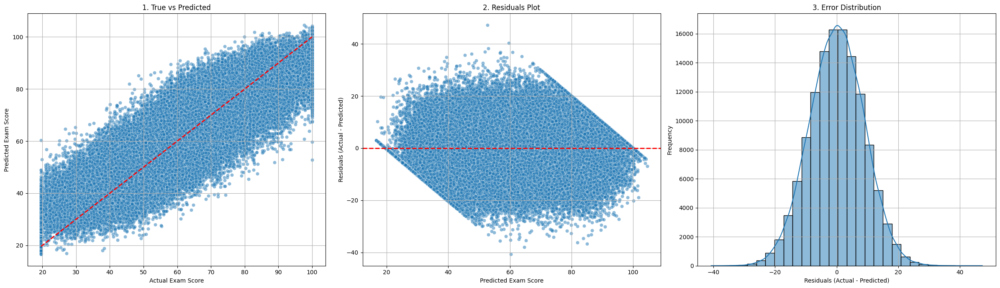

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals_xgb = y_test - y_pred_xgb

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_xgb, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_xgb, y=residuals_xgb, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals_xgb, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test date and save

In [ ]:
test_pred_xgb = best_xgb_model.predict(test_variables)

sample_submission["exam_score"] = test_pred_xgb
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_xgb.csv", index=False)

# HistGradientBoostingRegressor

Take a smaller sample of data

In [ ]:
X_train_sample = X_train.sample(n=50000, random_state=42)
y_train_sample = y_train.sample(n=50000, random_state=42)

Find best hyperparameters on small sample

In [ ]:
param_grid_hgb = {
    "max_iter": [100, 200, 300],
    "max_depth": [None, 4, 8, 16],
    "learning_rate": [0.1, 0.3, 0.5, 0.7, 0.9],
    "min_samples_leaf": [1, 3, 5, 7]
}

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(random_state=42)
grid_search_hgb = GridSearchCV(hgb_model, param_grid_hgb, scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1, verbose=3)
grid_search_hgb.fit(X_train_sample, y_train_sample)

best_hgb_model = grid_search_hgb.best_estimator_
print(f"Best HistGradientBoostingRegressor model parameters: {grid_search_hgb.best_params_}")

Fitting 5 folds for each of 240 candidates, totalling 1200 fits
Best HistGradientBoostingRegressor model parameters: {'learning_rate': 0.1, 'max_depth': 4, 'max_iter': 200, 'min_samples_leaf': 3}


Test model with best hyperparameters

In [ ]:
best_hgb_model.fit(X_train, y_train)
y_pred_hgb = best_hgb_model.predict(X_test)

mse_hgb = mean_squared_error(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mse_hgb)
r2_hgb = r2_score(y_test, y_pred_hgb)

print(f"\nHistGradientBoostingRegressor Model Performance:")
print(f"  Mean Squared Error (MSE): {mse_hgb:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_hgb:.2f}")
print(f"  R-squared (R2): {r2_hgb:.2f}")


HistGradientBoostingRegressor Model Performance:
  Mean Squared Error (MSE): 77.52
  Root Mean Squared Error (RMSE): 8.80
  R-squared (R2): 0.78


Visualize results

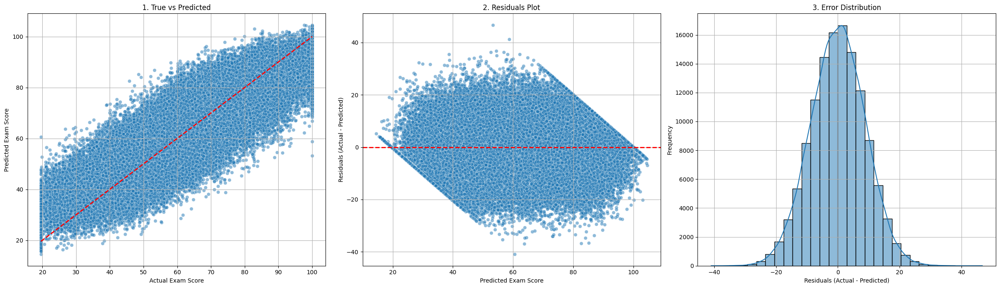

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals_hgb = y_test - y_pred_hgb

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_hgb, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_hgb, y=residuals_hgb, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals_hgb, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test data and save

In [ ]:
test_pred_hgb = best_hgb_model.predict(test_variables)

sample_submission["exam_score"] = test_pred_hgb
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_xgb.csv", index=False)

# **Stacking Regressor**

Recap of best models

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

linear_model = LinearRegression()
best_svr_model = SVR(kernel="linear", epsilon=1.0, C=21)
best_rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=None, min_samples_leaf=7, min_samples_split=2)
best_hgb_model = HistGradientBoostingRegressor(random_state=42, learning_rate=0.1, max_depth=4, max_iter=200, min_samples_leaf=3)

Take a smaller sample of data

In [ ]:
X_train_sample = X_train.sample(n=20000, random_state=42)
y_train_sample = y_train.sample(n=20000, random_state=42)

Test model on small sample

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge

estimators = [
    ("lr", linear_model),
    ("svr", best_svr_model),
    ("rf", best_rf_model),
    ("hgb", best_hgb_model)
]

meta_estimator = Ridge(random_state=42)
stacking_regressor = StackingRegressor(estimators, meta_estimator, cv=5, n_jobs=-1)

stacking_regressor.fit(X_train_sample, y_train_sample)
y_pred_stacking = stacking_regressor.predict(X_test)

mse_stacking = mean_squared_error(y_test, y_pred_stacking)
rmse_stacking = np.sqrt(mse_stacking)
r2_stacking = r2_score(y_test, y_pred_stacking)

print(f"\nStacking Regressor Performance:")
print(f"  Mean Squared Error (MSE): {mse_stacking:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_stacking:.2f}")
print(f"  R-squared (R2): {r2_stacking:.2f}")


Stacking Regressor Performance:
  Mean Squared Error (MSE): 78.55
  Root Mean Squared Error (RMSE): 8.86
  R-squared (R2): 0.78


Visualize data

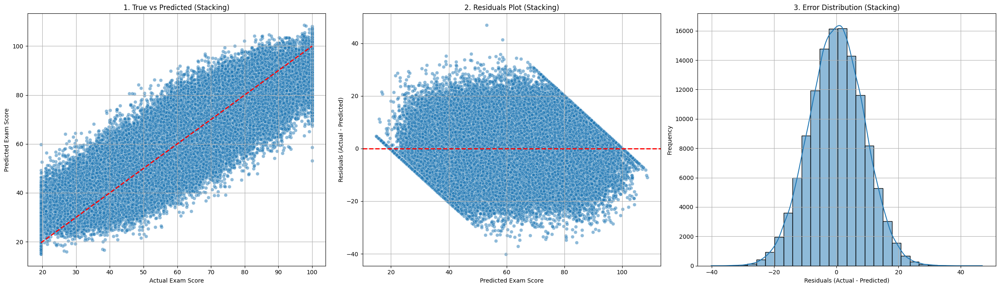

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals_stacking = y_test - y_pred_stacking

plt.figure(figsize=(24, 7))

# Plot 1: True vs Predicted
plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred_stacking, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("1. True vs Predicted (Stacking)")
plt.grid(True)

# Plot 2: Residuals Plot (Predicted vs. Residuals)
plt.subplot(1, 3, 2)
sns.scatterplot(x=y_pred_stacking, y=residuals_stacking, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("2. Residuals Plot (Stacking)")
plt.grid(True)

# Plot 3: Error Distribution Plot (Histogram of Residuals)
plt.subplot(1, 3, 3)
sns.histplot(residuals_stacking, kde=True, bins=30)
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("3. Error Distribution (Stacking)")
plt.grid(True)

plt.tight_layout()
plt.show()

Apply model to real test data and save

In [ ]:
test_pred_stacking = stacking_regressor.predict(test_variables)

sample_submission["exam_score"] = test_pred_stacking
sample_submission.to_csv("gdrive/My Drive/Colab Notebooks/sample_submission_stacking.csv", index=False)